# 08 Exploratory associations between model and Self-reports

Question: Do classifier stress scores on subjects excluded from training covary with self-reported stress?

This notebook does not train models and does not use questionnaires as labels. It uses one row per subject and condition. Analyses are exploratory, defined after inspecting the main results: they do not constitute ecological or clinical validation.

**Prerequisite:** Run the corrected self-report block of notebook 07 and save `exploratory/results/self_report_episode_scores.csv`. Verify item encoding against the original README. STAI measures state anxiety; the "stressed" item is a single measure, not a full stress scale.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, wilcoxon
from IPython.display import display, Markdown, Image
from io import BytesIO

# Se il notebook è nella cartella notebooks/, la root viene trovata automaticamente.
# Modifica PROJECT_ROOT solo se esegui il notebook da un'altra cartella.
PROJECT_ROOT = None
here = Path.cwd().resolve()
candidates = [here, *here.parents]
ROOT = (Path(PROJECT_ROOT).resolve() if PROJECT_ROOT else
        next((p for p in candidates if (p/'configs/config.yaml').is_file()
              and (p/'src').is_dir()), None))
if ROOT is None:
    raise RuntimeError('Salva questo notebook nella cartella notebooks del progetto oppure imposta PROJECT_ROOT.')

# Usa gli artefatti reali già prodotti.
ARTIFACTS = ROOT / 'artifacts/revision_v2'
import sys
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.provenance import verify_lock
verify_lock(ARTIFACTS / 'protocol_lock.json')
PREDICTIONS = ARTIFACTS / 'results/secondary_stress_vs_nonstress_wrist_predictions.csv'
REPORTS = ARTIFACTS / 'exploratory/results/self_report_episode_scores.csv'
OUT = ARTIFACTS / 'exploratory/model_self_report_associations'
OUT.mkdir(parents=True, exist_ok=True)
for path in [PREDICTIONS, REPORTS]:
    if not path.is_file():
        raise FileNotFoundError(f'File necessario assente: {path}')

SEED = 42
N_PERMUTATIONS = 19999
N_BOOTSTRAP = 5000
def show_figure(fig, name):
    fig.savefig(OUT / name, dpi=160, bbox_inches='tight')
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
        data = buffer.getvalue()
    plt.close(fig)
    display(Image(data=data))



## Input verification and aggregation

A fixed model is used: wrist logistic regression for stress/non-stress. The probability is a classifier score, not a validated measure of intensity. Each subject is evaluated by a distinct LOSO model. No model selection was performed based on correlations.

The proportion of windows predicted as stress does not equal the percentage of time: overlapping windows and QC exclusions prevent such a direct interpretation. During TSST, this proportion coincides with stress recall across the available windows.

In [3]:
pred = pd.read_csv(PREDICTIONS)
reports = pd.read_csv(REPORTS)
metadata_path = PREDICTIONS.with_name(PREDICTIONS.name.replace('_predictions.csv', '.json'))
metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
if metadata['task'] != 'stress_vs_nonstress' or metadata['model'] != 'logistic_regression' or metadata['site'] != 'wrist':
    raise ValueError('Esperimento diverso da quello previsto.')
if metadata['classes'] != [0, 1]:
    raise ValueError('Ordine classi inatteso.')
if pred.duplicated(['subject_id','window_id']).any():
    raise ValueError('Predizioni duplicate.')
if reports.duplicated(['subject_id','condition']).any():
    raise ValueError('Questionari duplicati per soggetto e condizione.')
p = pred[['p_0','p_1']].to_numpy(float)
if not np.isfinite(p).all() or (p < 0).any() or (p > 1).any() or not np.allclose(p.sum(1), 1):
    raise ValueError('Probabilità non valide.')

# Recupera le condizioni originali: nel task binario baseline e amusement sono entrambe 0.
original_file = ARTIFACTS / 'results/confirmatory_wrist_logistic_regression_predictions.csv'
original = pd.read_csv(original_file)
if original.duplicated(['subject_id','window_id']).any():
    raise ValueError('Finestre originali duplicate.')
pred = pred.merge(original[['subject_id','window_id','label']].rename(columns={'label':'original_label'}),
                  on=['subject_id','window_id'], how='left', validate='one_to_one')
if pred['original_label'].isna().any():
    raise ValueError('Impossibile ricostruire la condizione di alcune finestre.')
if not pred['label'].eq(pred['original_label'].eq(2).astype(int)).all():
    raise ValueError('Etichette binarie discordanti con le condizioni originali.')
pred['condition'] = pred['original_label'].map({1:'Base',2:'TSST',3:'Fun'})
pred['predicted_stress'] = pred['p_1'] > pred['p_0']  # argmax: parità -> classe 0
aggregated = pred.groupby(['subject_id','condition']).agg(
    n_windows=('window_id','size'), mean_stress_probability=('p_1','mean'),
    fraction_predicted_stress=('predicted_stress','mean')).reset_index()
data = aggregated.merge(reports, on=['subject_id','condition'], how='left',
                        validate='one_to_one', indicator=True)
display(data[['subject_id','condition','n_windows','mean_stress_probability',
              'fraction_predicted_stress','stressed_item','stai6_keyed_sum','_merge']])
print('Episodi senza questionario:', int(data['_merge'].ne('both').sum()))
data.drop(columns='_merge').to_csv(OUT/'subject_condition_data.csv', index=False)


,subject_id,condition,n_windows,mean_stress_probability,fraction_predicted_stress,stressed_item,stai6_keyed_sum,_merge
0,2,Base,37,0.046070,0.000000,2.0,10.0,both
1,2,Fun,11,0.205001,0.090909,1.0,8.0,both
2,2,TSST,17,0.630149,0.764706,3.0,20.0,both
3,3,Base,37,0.097176,0.081081,1.0,9.0,both
4,3,Fun,11,0.134261,0.000000,1.0,9.0,both
5,3,TSST,18,0.736837,0.888889,4.0,20.0,both
6,4,Base,37,0.076346,0.000000,1.0,9.0,both
7,4,Fun,11,0.017928,0.000000,1.0,8.0,both
8,4,TSST,20,0.921611,1.000000,2.0,17.0,both
9,5,Base,32,0.112918,0.093750,2.0,10.0,both


Episodi senza questionario: 0


## Statistical methods and exploratory plan

Primary analysis of this exploration: mean stress probability during TSST versus the stressed item. Additional analyses: STAI, proportion of windows classified as stress, and TSST−baseline change. Spearman's rank correlation handles ordinal responses, but does not eliminate uncertainty or confounding.

The two-sided p-value is estimated by permuting subject pairings (hypothesis: independent subjects and exchangeable pairings under the null of independence). It does not test every possible form of null correlation. Bootstrap resampling resamples subject pairs; intervals are approximate and conditional on already trained models. They do not include LOSO retraining. Association p-values are corrected using Holm's method as a single family; intervals remain non-simultaneous.

In [4]:
def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    order = good[np.argsort(pvalues[good])]
    if len(order):
        adjusted = np.maximum.accumulate(pvalues[order] * np.arange(len(order), 0, -1))
        result[order] = np.minimum(adjusted, 1)
    return result

def association(x, y, seed=SEED):
    pairs = pd.DataFrame({'x':x,'y':y}).replace([np.inf,-np.inf], np.nan).dropna()
    x, y = pairs.x.to_numpy(float), pairs.y.to_numpy(float)
    n = len(x)
    result = dict(n=n, rho=np.nan, ci_low=np.nan, ci_high=np.nan,
                  p_permutation=np.nan, valid_bootstrap=0)
    if n < 4 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return result
    rng = np.random.default_rng(seed)
    rx, ry = rankdata(x), rankdata(y)
    rx, ry = rx-rx.mean(), ry-ry.mean()
    denominator = np.linalg.norm(rx)*np.linalg.norm(ry)
    rho = float(rx @ ry / denominator)
    extreme = 0
    for _ in range(N_PERMUTATIONS):
        r = float(rx @ rng.permutation(ry) / denominator)
        extreme += abs(r) >= abs(rho)-1e-12
    boot = []
    for _ in range(N_BOOTSTRAP):
        index = rng.integers(0, n, size=n)
        bx, by = x[index], y[index]
        if np.unique(bx).size > 1 and np.unique(by).size > 1:
            boot.append(float(spearmanr(bx, by).statistic))
    low, high = np.quantile(boot, [.025,.975]) if boot else (np.nan,np.nan)
    result.update(rho=rho, ci_low=low, ci_high=high,
                  p_permutation=(extreme+1)/(N_PERMUTATIONS+1), valid_bootstrap=len(boot))
    return result

wide = data.pivot(index='subject_id', columns='condition',
                  values=['mean_stress_probability','fraction_predicted_stress',
                          'stressed_item','stai6_keyed_sum'])
delta = pd.DataFrame(index=wide.index)
for variable in ['mean_stress_probability','fraction_predicted_stress','stressed_item','stai6_keyed_sum']:
    delta[variable] = wide[(variable,'TSST')] - wide[(variable,'Base')]
delta.to_csv(OUT/'subject_changes_TSST_minus_Base.csv')
tsst = data[data.condition.eq('TSST')].set_index('subject_id')
specifications = [
    (
        'TSST: mean stress probability vs self-reported stress',
        tsst,
        'mean_stress_probability',
        'stressed_item',
    ),
    (
        'TSST: mean stress probability vs STAI',
        tsst,
        'mean_stress_probability',
        'stai6_keyed_sum',
    ),
    (
        'TSST: fraction predicted as stress vs self-reported stress',
        tsst,
        'fraction_predicted_stress',
        'stressed_item',
    ),
    (
        'TSST: fraction predicted as stress vs STAI',
        tsst,
        'fraction_predicted_stress',
        'stai6_keyed_sum',
    ),
    (
        'Change: mean stress probability vs self-reported stress',
        delta,
        'mean_stress_probability',
        'stressed_item',
    ),
    (
        'Change: mean stress probability vs STAI',
        delta,
        'mean_stress_probability',
        'stai6_keyed_sum',
    ),
]
rows = []
for i, (name, frame, xcol, ycol) in enumerate(specifications):
    rows.append({'analysis':name, **association(frame[xcol], frame[ycol], SEED+i)})
associations = pd.DataFrame(rows)
associations['p_holm'] = holm_adjust(associations.p_permutation)
display(associations.style.format({k:'{:.3f}' for k in
    ['rho','ci_low','ci_high','p_permutation','p_holm']}, na_rep='N/D'))
associations.to_csv(OUT/'spearman_associations.csv', index=False)


,analysis,n,rho,ci_low,ci_high,p_permutation,valid_bootstrap,p_holm
0,TSST: mean stress probability vs self-reported stress,15,0.320,-0.242,0.741,0.238,5000,1.000
1,TSST: mean stress probability vs STAI,15,0.221,-0.373,0.700,0.425,5000,1.000
2,TSST: fraction predicted as stress vs self-reported stress,15,0.221,-0.317,0.693,0.434,4997,1.000
3,TSST: fraction predicted as stress vs STAI,15,0.131,-0.478,0.631,0.644,4997,1.000
4,Change: mean stress probability vs self-reported stress,15,0.131,-0.409,0.593,0.638,5000,1.000
5,Change: mean stress probability vs STAI,15,0.233,-0.314,0.706,0.392,5000,1.000


## Plots and sensitivity to individual subjects

Each point represents an individual. Labels allow for the identification of influential observations. No subjects are removed based on correlation improvement. The subsequent leave-one-subject-out check measures correlation sensitivity; it is not a new machine learning training step.

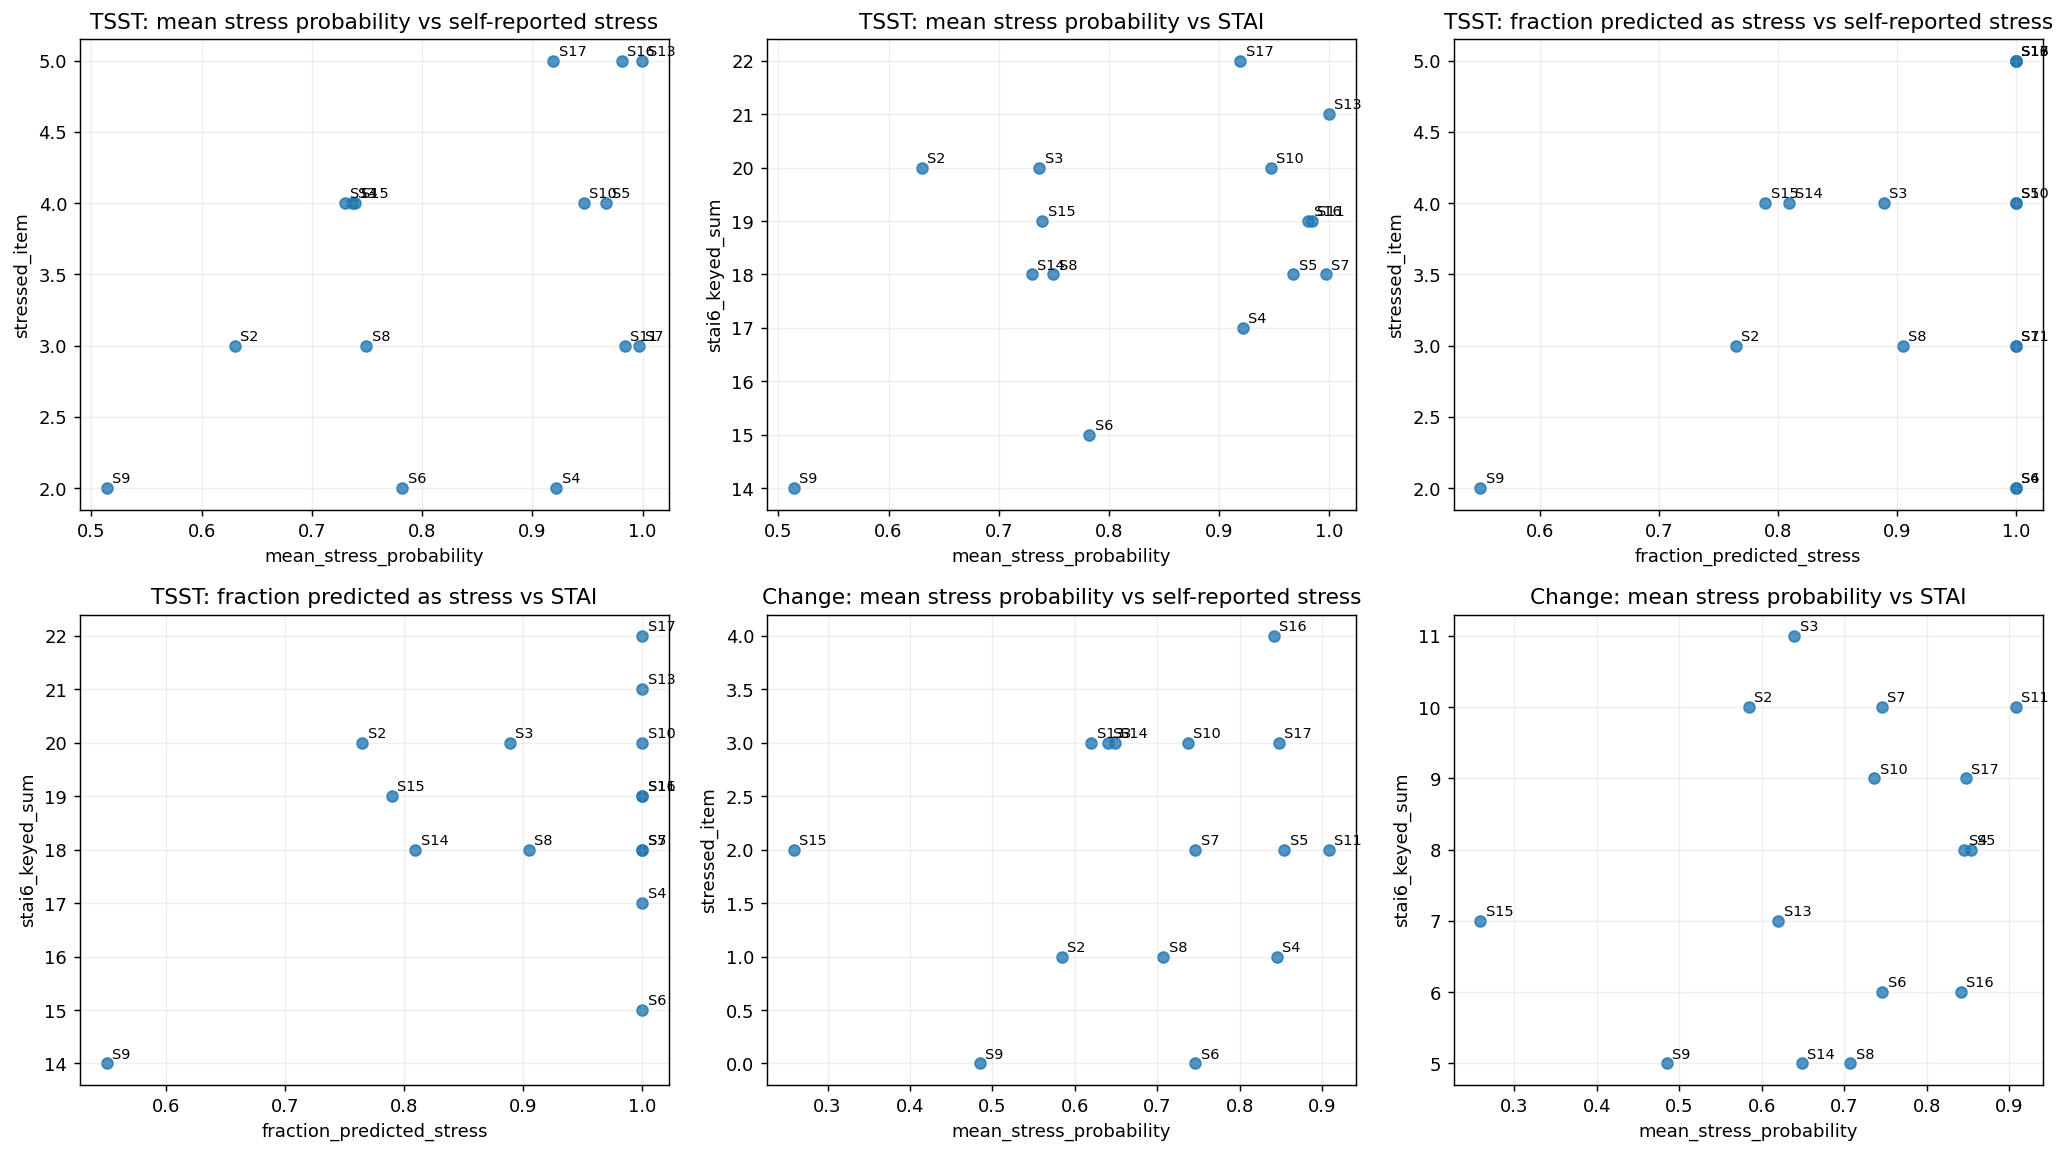

,min,max,count
analysis,,,
Change: mean stress probability vs STAI,0.097674,0.378653,15
Change: mean stress probability vs self-reported stress,-0.029703,0.205148,15
TSST: fraction predicted as stress vs STAI,-0.107157,0.242234,15
TSST: fraction predicted as stress vs self-reported stress,0.055985,0.338197,15
TSST: mean stress probability vs STAI,0.038124,0.337478,15
TSST: mean stress probability vs self-reported stress,0.178429,0.412575,15


In [5]:
sensitivity_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16,9))
for ax, (name, frame, xcol, ycol) in zip(axes.flat, specifications):
    complete = frame[[xcol,ycol]].replace([np.inf,-np.inf],np.nan).dropna()
    ax.scatter(complete[xcol],complete[ycol], alpha=.8)
    for sid, row in complete.iterrows():
        ax.annotate(f'S{int(sid)}', (row[xcol],row[ycol]), fontsize=8,
                    xytext=(3,3), textcoords='offset points')
    ax.set(title=name, xlabel=xcol, ylabel=ycol)
    ax.grid(alpha=.2)
    for sid in complete.index:
        reduced = complete.drop(index=sid)
        rho = (float(spearmanr(reduced[xcol],reduced[ycol]).statistic)
               if len(reduced)>=3 and reduced[xcol].nunique()>1 and reduced[ycol].nunique()>1
               else np.nan)
        sensitivity_rows.append({'analysis':name,'excluded_subject':int(sid),'rho':rho})
fig.tight_layout()
show_figure(fig, 'associations_scatter.png')
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.groupby('analysis').rho.agg(['min','max','count']))
sensitivity.to_csv(OUT/'leave_one_subject_out_sensitivity.csv', index=False)


## Self-report verification: baseline versus TSST

Distinct question from correlations: Does reported experience change between conditions within the same individual? Paired differences and two-sided Wilcoxon signed-rank tests with asymptotic approximation, zero handling, and Holm correction across the two scores are reported. With few subjects, many ties, and discrete differences, the p-value must be interpreted with caution. The signed-rank test requires assumptions regarding the distribution of differences; it is not a generic proof of median difference across every distribution.

,score,n,median_baseline,median_TSST,median_paired_change,n_increase,n_ties,statistic,p_wilcoxon_approx,p_holm
0,stressed_item,15,2.0,4.0,2.0,13,2,0.0,0.001312,0.001312
1,stai6_keyed_sum,15,10.0,19.0,8.0,15,0,0.0,0.000635,0.001271


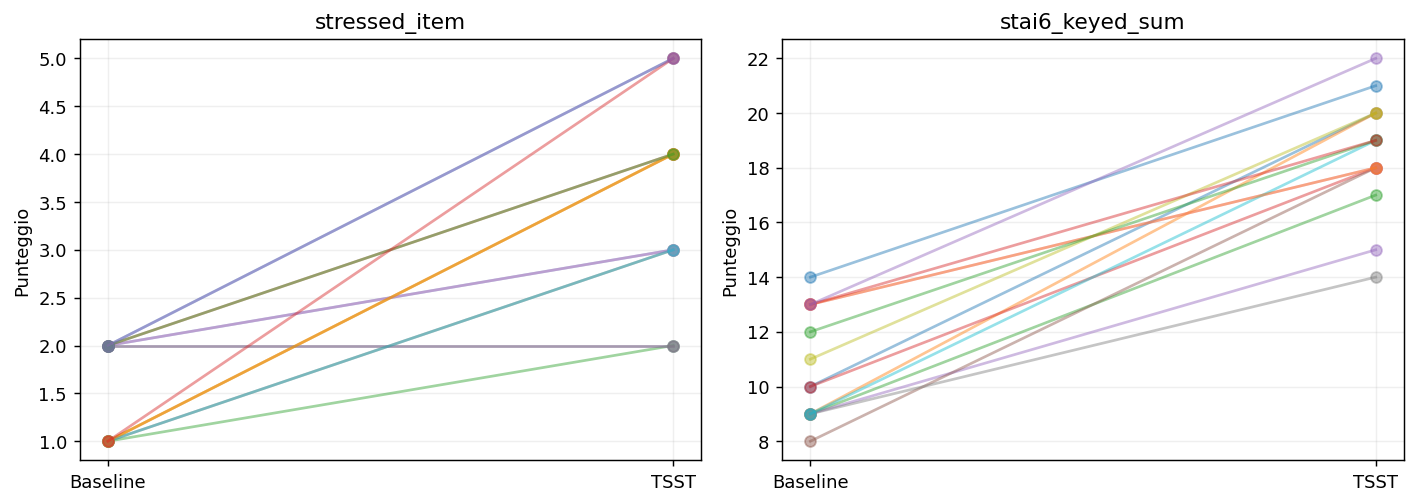

In [6]:
change_rows = []
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, score in zip(axes,['stressed_item','stai6_keyed_sum']):
    pairs = wide[score][['Base','TSST']].dropna()
    differences = pairs['TSST']-pairs['Base']
    if len(pairs)<3:
        statistic, pvalue = np.nan, np.nan
    elif differences.eq(0).all():
        statistic, pvalue = 0., 1.
    else:
        test = wilcoxon(pairs['TSST'], pairs['Base'], zero_method='wilcox',
                        alternative='two-sided', method='approx')
        statistic, pvalue = float(test.statistic),float(test.pvalue)
    change_rows.append({'score':score,'n':len(pairs),
        'median_baseline':pairs.Base.median(),'median_TSST':pairs.TSST.median(),
        'median_paired_change':differences.median(),
        'n_increase':int(differences.gt(0).sum()),'n_ties':int(differences.eq(0).sum()),
        'statistic':statistic,'p_wilcoxon_approx':pvalue})
    for sid,row in pairs.iterrows():
        ax.plot([0,1],row.to_numpy(), 'o-',alpha=.45)
    ax.set(xticks=[0,1],xticklabels=['Baseline','TSST'],title=score,ylabel='Punteggio')
    ax.grid(alpha=.2)
changes = pd.DataFrame(change_rows)
changes['p_holm'] = holm_adjust(changes.p_wilcoxon_approx)
display(changes)
changes.to_csv(OUT/'paired_self_report_changes.csv',index=False)
fig.tight_layout()
show_figure(fig,'paired_self_report_changes.png')


In [7]:
manifest = {
    "analysis_role": "exploratory_post_hoc",
    "predictions": PREDICTIONS.name,
    "self_reports": REPORTS.name,
    "model": (
        "wrist logistic regression, stress_vs_nonstress, "
        "saved LOSO test predictions"
    ),
    "unit": "subject within condition; paired subject changes",
    "n_permutations": N_PERMUTATIONS,
    "n_bootstrap": N_BOOTSTRAP,
    "seed": SEED,
    "multiplicity": (
        "Holm within six associations; separately within two paired tests"
    ),
    "uncertainty": (
        "conditional on fitted models; no retraining; exploratory assumptions"
    ),
    "scoring": "verify item mapping against original dataset documentation",
}

(OUT / "analysis_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("Tabeles, figures and manifest saved.")


Tabeles, figures and manifest saved.


## Interpretation of model–self-report associations

### Analysis scope and data completeness

This notebook examines whether outputs from the **wrist logistic-regression
stress/non-stress classifier** are associated with participants'
self-reported stress and state anxiety.

All model outputs are **held-out LOSO predictions**. Questionnaires were
not used to train the classifier.

The analysis includes **15 participants**, with matched model summaries and
questionnaires for baseline, stress/TSST, and amusement. No evaluated
participant–condition episode is missing its questionnaire.

Windows are aggregated within participant and condition. The independent
analysis unit is therefore the participant, not the individual window.

### 1. Associations during the stress condition

The main exploratory question is whether participants with higher average
model stress probabilities during TSST also report greater stress.

| Association during TSST | n | Spearman rho | Bootstrap 95% CI | Permutation p | Holm-adjusted p |
|---|---:|---:|---|---:|---:|
| Mean stress probability vs. stressed item | 15 | 0.320 | [−0.242, 0.741] | 0.238 | 1.000 |
| Mean stress probability vs. STAI | 15 | 0.221 | [−0.373, 0.700] | 0.425 | 1.000 |
| Fraction predicted as stress vs. stressed item | 15 | 0.221 | [−0.317, 0.693] | 0.434 | 1.000 |
| Fraction predicted as stress vs. STAI | 15 | 0.131 | [−0.478, 0.631] | 0.644 | 1.000 |

All point estimates are positive, but the intervals are wide and include
zero. None of the associations is statistically significant at the
conventional 0.05 level, before or after Holm correction.

The strongest observed association is between mean stress probability
and the stressed item, with **rho = 0.320**. Its uncertainty does not support
a firm conclusion about a population-level association.

These results do not demonstrate that the classifier probability measures
the intensity of perceived stress. They also do not establish the absence
of an association: the small sample leaves substantial uncertainty.

### 2. Changes from baseline to TSST

The change analysis subtracts each participant's baseline value from their
TSST value for both model probability and self-report.

| Association between TSST−baseline changes | n | Spearman rho | Bootstrap 95% CI | Permutation p | Holm-adjusted p |
|---|---:|---:|---|---:|---:|
| Change in mean stress probability vs. change in stressed item | 15 | 0.131 | [−0.409, 0.593] | 0.638 | 1.000 |
| Change in mean stress probability vs. change in STAI | 15 | 0.233 | [−0.314, 0.706] | 0.392 | 1.000 |

Neither analysis provides clear evidence that participants with larger
subjective changes also have larger changes in model probability.

This is distinct from asking whether average self-reports increase during
TSST. A condition can shift both physiological model scores and subjective
ratings without their individual changes being strongly correlated.

### 3. Sensitivity to individual participants

The leave-one-participant-out correlation check evaluates how much the
association changes when one participant is omitted. It does not refit
the machine-learning classifier.

| Association | Minimum rho | Maximum rho |
|---|---:|---:|
| TSST probability vs. stressed item | 0.178 | 0.413 |
| TSST probability vs. STAI | 0.038 | 0.337 |
| TSST fraction predicted stress vs. stressed item | 0.056 | 0.338 |
| TSST fraction predicted stress vs. STAI | −0.107 | 0.242 |
| Probability change vs. stressed-item change | −0.030 | 0.205 |
| Probability change vs. STAI change | 0.098 | 0.379 |

Several estimates change appreciably after removing a single participant.
Two associations can change sign.

These ranges illustrate sensitivity in a small sample. They are not
confidence intervals and should not be used to select a favorable subset.
No participant should be removed merely to increase a correlation.

### 4. Self-reported responses increase from baseline to TSST

The paired questionnaire analysis addresses a different question:
whether reported experience changes between the two conditions.

| Measure | n | Baseline median | TSST median | Median paired change | Participants increasing | Ties | Wilcoxon statistic | Approximate p | Holm-adjusted p |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Stressed item | 15 | 2.0 | 4.0 | +2.0 | 13 | 2 | 0.0 | 0.001312 | 0.001312 |
| STAI-6 keyed sum | 15 | 10.0 | 19.0 | +8.0 | 15 | 0 | 0.0 | 0.000635 | 0.001271 |

Self-reported stress increases in **13 participants**, with two unchanged.
STAI increases in **all 15 participants**.

Both comparisons remain below 0.05 after Holm correction across these
two tests. Under the signed-rank test assumptions, the results support
higher reported stress and state anxiety during TSST than during baseline.

The median paired change is calculated from individual differences. It
does not have to equal the difference between the two condition medians:
for STAI, the median individual change is **8**, whereas the difference
between condition medians is **9**.

The tests use an asymptotic approximation. Small sample size, discrete
responses, ties, and assumptions about paired differences should be
considered when interpreting the p-values. Questionnaire scoring must
also be verified against the original documentation.

### 5. Why the questionnaire and correlation results are not contradictory

The paired tests show a consistent **within-participant increase in
self-reported stress and anxiety** during TSST.

The correlations ask whether **differences between participants** in those
responses align with differences in classifier scores. These are separate
statistical questions.

The present results support a subjective condition difference but do not
provide clear evidence that the model ranks participants by perceived
stress intensity.

During TSST, the fraction of windows predicted as stress is the classifier's
stress recall on the available windows. It is not a validated intensity
measure. High recall and limited variation near its upper bound can also
restrict the information available for correlation.

### Methodological boundaries

- Each participant is evaluated by a different fitted LOSO model.
  Between-participant probability differences may reflect model behavior
  and calibration as well as physiological variation.
- Aggregation uses available valid windows, which may not represent every
  moment of the experimental block.
- Overlapping windows are not independent questionnaire observations.
- The proportion of windows classified as stress is not directly the
  proportion of recording time spent experiencing stress.
- Bootstrap intervals and permutation tests are exploratory and conditional
  on the saved model outputs.
- The six association tests form one Holm-corrected family; the two paired
  questionnaire tests form a separate family.
- A low self-report does not retroactively make a classification error
  correct relative to the experimental label.
- No association establishes causality, ecological validity, or clinical
  validity.

### Conclusion

Participants report greater stress and state anxiety during TSST than
during baseline. However, this sample does not provide clear statistical
evidence that held-out classifier scores track individual differences
in subjective stress or anxiety.

The findings support keeping **experimental-condition classification**
and **measurement of subjective intensity** conceptually separate.
They motivate further investigation with a larger independent sample,
rather than claiming psychological validation of the classifier.